In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create hypothetical logistics data
np.random.seed(42)

n = 120

data = {
    "Shipment_ID": range(1, n + 1),
    "Distance_km": np.random.randint(50, 1000, n),
    "Shipment_Weight_kg": np.random.randint(100, 2000, n),
    "Traffic_Level": np.random.choice(
        ["Low", "Medium", "High"], n
    ),
    "Transport_Mode": np.random.choice(
        ["Road", "Rail", "Air"], n
    )
}

df = pd.DataFrame(data)

# Simulate delivery time
df["Delivery_Time_hr"] = (
    df["Distance_km"] / 50
    + np.random.uniform(1, 5, n)
)

# Simulate transportation cost
df["Transport_Cost_INR"] = (
    df["Distance_km"] * 2
    + df["Shipment_Weight_kg"] * 0.5
    + np.random.randint(100, 500, n)
)

print("First five records:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nDataset information:")
print(df.info())

# Save dataset
df.to_csv("Week_3_Logistics_Data.csv", index=False)

First five records:
   Shipment_ID  Distance_km  Shipment_Weight_kg Traffic_Level Transport_Mode  \
0            1          152                 592          High           Road   
1            2          485                1164           Low           Road   
2            3          910                1280        Medium            Air   
3            4          320                 114           Low            Air   
4            5          156                1936           Low           Rail   

   Delivery_Time_hr  Transport_Cost_INR  
0          6.202540               808.0  
1         13.249720              1832.0  
2         22.104365              2601.0  
3         11.303408               982.0  
4          6.185201              1777.0  

Dataset shape:
(120, 7)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  ----- 

In [3]:
# Summary statistics
print("Statistical Summary:")
print(df.describe())

# Mean and median delivery time
print("\nMean Delivery Time:")
print(df["Delivery_Time_hr"].mean())

print("\nMedian Delivery Time:")
print(df["Delivery_Time_hr"].median())

# Average transportation cost
print("\nAverage Transportation Cost:")
print(df["Transport_Cost_INR"].mean())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Correlation between numerical variables
print("\nCorrelation Matrix:")
print(
    df[
        [
            "Distance_km",
            "Shipment_Weight_kg",
            "Delivery_Time_hr",
            "Transport_Cost_INR"
        ]
    ].corr()
)

Statistical Summary:
       Shipment_ID  Distance_km  Shipment_Weight_kg  Delivery_Time_hr  \
count   120.000000   120.000000          120.000000        120.000000   
mean     60.500000   510.975000         1149.925000         13.252273   
std      34.785054   271.166124          531.624293          5.648185   
min       1.000000    51.000000          114.000000          2.582915   
25%      30.750000   292.500000          723.250000          8.984134   
50%      60.500000   506.500000         1157.500000         12.722678   
75%      90.250000   756.250000         1600.250000         18.502781   
max     120.000000   992.000000         1995.000000         24.129888   

       Transport_Cost_INR  
count          120.000000  
mean          1889.570833  
std            614.994778  
min            646.000000  
25%           1455.875000  
50%           1843.500000  
75%           2353.375000  
max           3163.500000  

Mean Delivery Time:
13.252273133924591

Median Delivery Time:
12.722

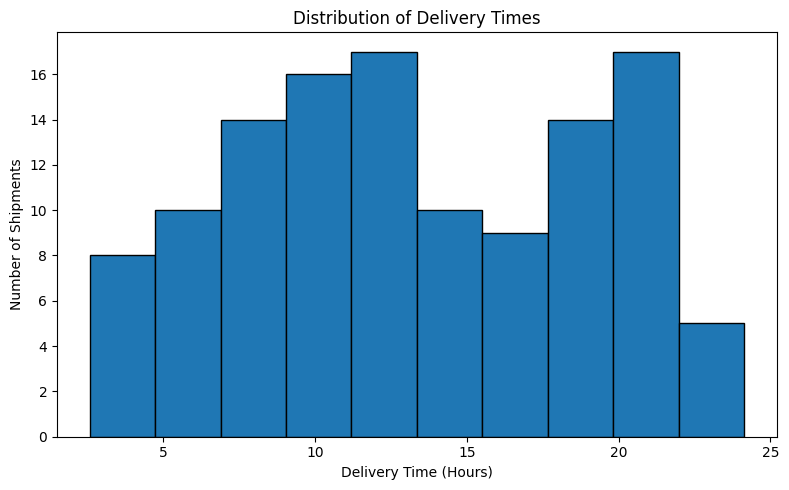

In [4]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["Delivery_Time_hr"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Delivery Times")
plt.xlabel("Delivery Time (Hours)")
plt.ylabel("Number of Shipments")

plt.tight_layout()
plt.show()

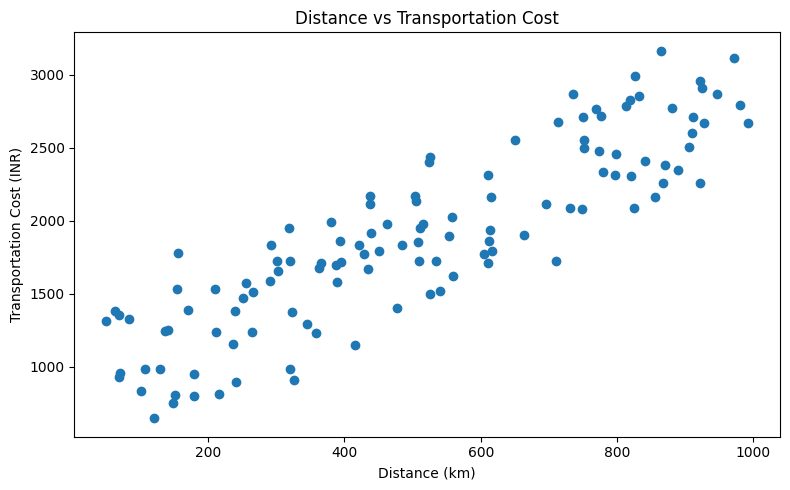

In [5]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Distance_km"],
    df["Transport_Cost_INR"]
)

plt.title("Distance vs Transportation Cost")
plt.xlabel("Distance (km)")
plt.ylabel("Transportation Cost (INR)")

plt.tight_layout()
plt.show()

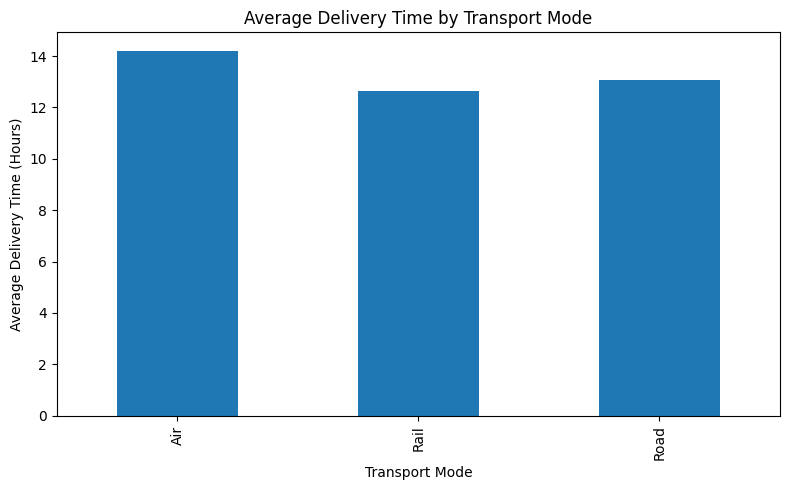

In [6]:
average_time = df.groupby(
    "Transport_Mode"
)["Delivery_Time_hr"].mean()

plt.figure(figsize=(8, 5))

average_time.plot(kind="bar")

plt.title("Average Delivery Time by Transport Mode")
plt.xlabel("Transport Mode")
plt.ylabel("Average Delivery Time (Hours)")

plt.tight_layout()
plt.show()


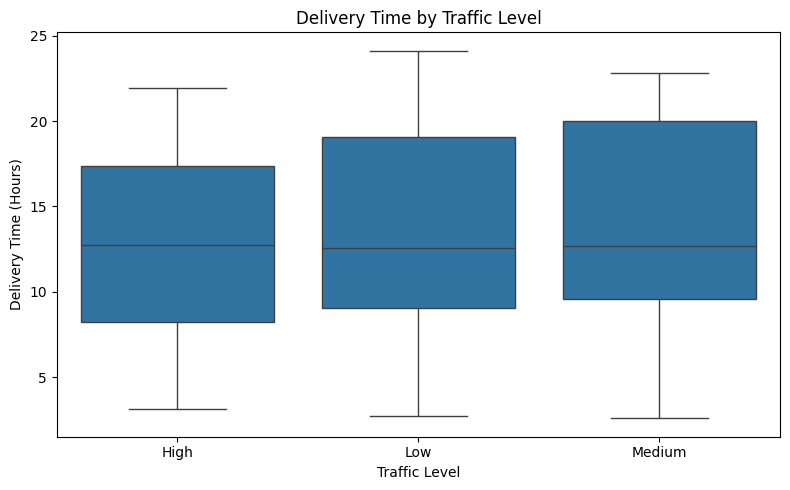

In [7]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Traffic_Level",
    y="Delivery_Time_hr"
)

plt.title("Delivery Time by Traffic Level")
plt.xlabel("Traffic Level")
plt.ylabel("Delivery Time (Hours)")

plt.tight_layout()
plt.show()

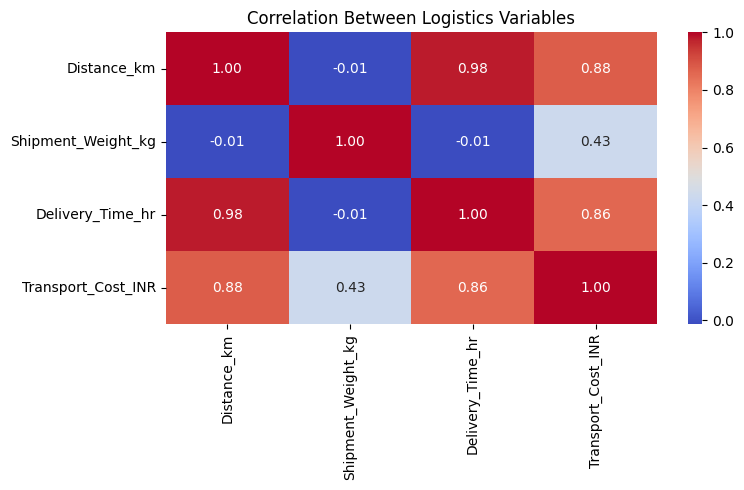

In [8]:
plt.figure(figsize=(8, 5))

numeric_data = df[
    [
        "Distance_km",
        "Shipment_Weight_kg",
        "Delivery_Time_hr",
        "Transport_Cost_INR"
    ]
]

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Logistics Variables")

plt.tight_layout()
plt.show()

In [9]:
from google.colab import files

files.download("Week_3_Logistics_Data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>